***LAB 02***

**SIMPLE AND MULTIPLE LINEAR REGRESSION**

*Task 01: SIMPLE LINEAR REGRESSION*

Load dataset

In [ ]:

from sklearn.datasets import load_diabetes
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

In [44]:
data= load_diabetes(as_frame=True).frame
data.to_csv('diabetes.csv', index=False)
print(data.head())
X=data[['bmi']]
Y=data[['target']]


        age       sex       bmi        bp        s1        s2        s3  \
0  0.038076  0.050680  0.061696  0.021872 -0.044223 -0.034821 -0.043401   
1 -0.001882 -0.044642 -0.051474 -0.026328 -0.008449 -0.019163  0.074412   
2  0.085299  0.050680  0.044451 -0.005670 -0.045599 -0.034194 -0.032356   
3 -0.089063 -0.044642 -0.011595 -0.036656  0.012191  0.024991 -0.036038   
4  0.005383 -0.044642 -0.036385  0.021872  0.003935  0.015596  0.008142   

         s4        s5        s6  target  
0 -0.002592  0.019907 -0.017646   151.0  
1 -0.039493 -0.068332 -0.092204    75.0  
2 -0.002592  0.002861 -0.025930   141.0  
3  0.034309  0.022688 -0.009362   206.0  
4 -0.002592 -0.031988 -0.046641   135.0  


Perform Exploratory Data Analysis (EDA):

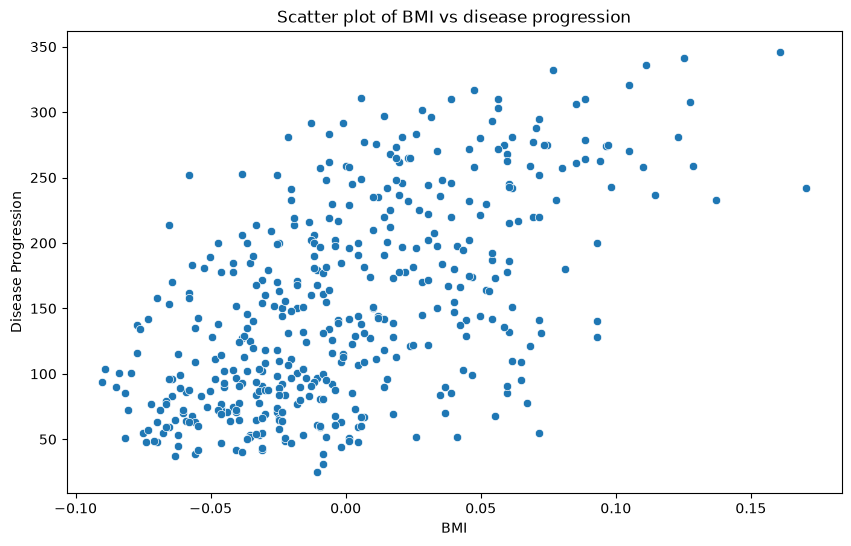

In [18]:
plt.figure(figsize=(10,6))
sns.scatterplot(x='bmi',y='target',data=data)
plt.title('Scatter plot of BMI vs disease progression')
plt.xlabel('BMI')
plt.ylabel('Disease Progression')
plt.show()

In [19]:
print(data['bmi'].corr(data['target']))

0.5864501344746885


correlation check whether two of the features are how much corelated to each other.....+ve means both are growing parallel...-ve means one grows other falls.....*both at some rate*....0.59 means paraleel and moderate relation between bmi and disease progression

Implement Simple Linear Regression

In [20]:
#split the data
x_train,x_test,y_train, y_test=train_test_split(X,Y,test_size=0.2,random_state=42)

In [22]:
#fit the model
model=LinearRegression()
model.fit(x_train,y_train)
y_pred=model.predict(x_test)


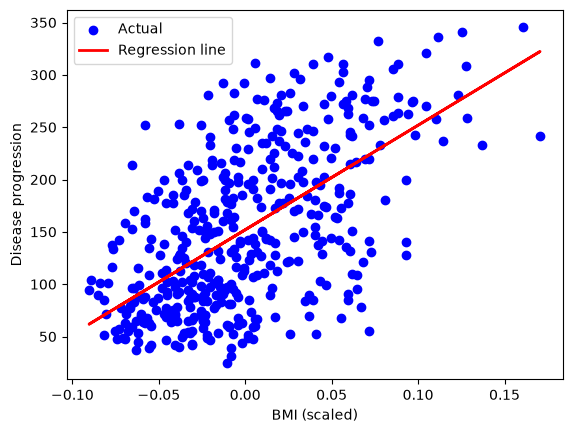

In [23]:
#Plot the regression line on the scatter plot.
#whole dataset 
plt.scatter(X, Y, color='blue', label='Actual')
plt.plot(X, model.predict(X), color='red', linewidth=2, label='Regression line')
plt.xlabel('BMI (scaled)')
plt.ylabel('Disease progression')
plt.legend()
plt.show()

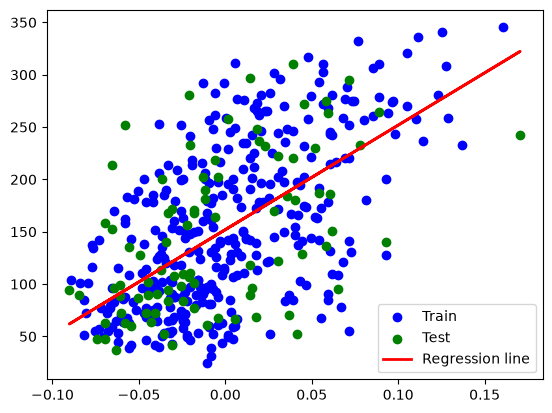

In [24]:
#plotting regression line with train and test data
plt.scatter(x_train, y_train, color='blue', label='Train')
plt.scatter(x_test, y_test, color='green', label='Test')
plt.plot(X, model.predict(X), color='red', linewidth=2, label='Regression line')
plt.legend()
plt.show()

Evaluate the model

In [25]:
#MSE
print('MSE =', mean_squared_error(y_test, y_pred))

#R2 Score
print('R2 Score =', r2_score(y_test, y_pred))

MSE = 4061.8259284949268
R2 Score = 0.23335039815872138


No, BMI alone does not explain most of the variation in disease progression.

The R² score is 0.23, which means the model's errors are about 23% smaller than
they would be if it simply predicted the average disease progression for every
patient. In other words, BMI explains only about 23% of the variation in the
target, and the remaining 77% is unexplained and comes from other factors not
included in the model.

R² helps here because it compares the model against the baseline of predicting
the mean, so it shows how much the feature actually adds. Since 23% is well below
50%, BMI alone is a weak predictor, and more features are needed (Task 2).

*Task 2: Multivariate Linear Regression*

Load dataset

In [29]:
X = data.drop(columns='target')   # all 10 features
Y = data['target']

Perform EDA

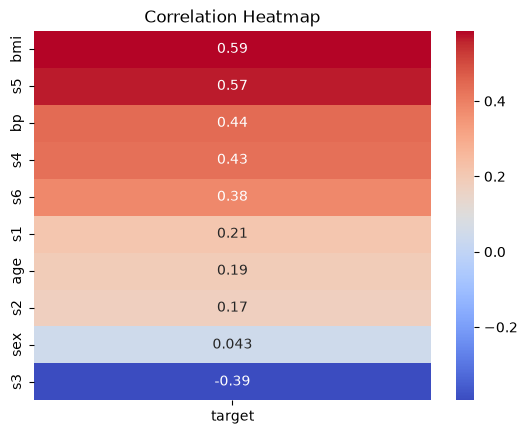

In [34]:
#Generate a correlation heatmap between features and the target.
corr_target= data.corr()[['target']].drop('target').sort_values(by='target',ascending=False)

sns.heatmap(corr_target,annot=True, cmap='coolwarm')
plt.title('Correlation Heatmap')
plt.show()

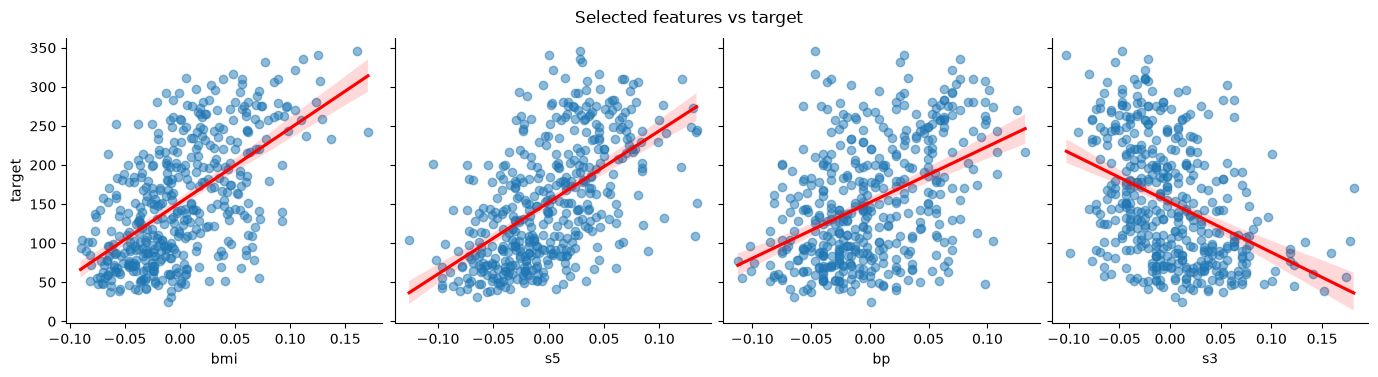

In [ ]:
#Create pair plots for selected features vs. target.
selected = ['bmi', 's5', 'bp', 's3']

sns.pairplot(data, x_vars=selected, y_vars='target', height=3.5, kind='reg',
             plot_kws={'line_kws': {'color': 'red'}, 'scatter_kws': {'alpha': 0.5}})
plt.suptitle('Selected features vs target', y=1.05)
plt.show()

Implement Multivariate Linear Regression

In [37]:
#Use all independent variables to predict the target.
X = data.drop(columns='target')   
Y = data['target']

X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.2, random_state=42)

model2 = LinearRegression()
model2.fit(X_train, Y_train)

Y_pred = model2.predict(X_test)

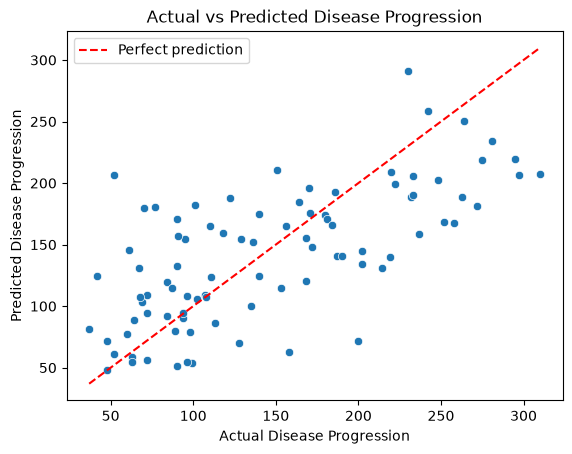

In [39]:
#Scatter plot (predicted vs. actual).
sns.scatterplot(x=Y_test, y=Y_pred)
plt.plot([Y_test.min(), Y_test.max()], [Y_test.min(), Y_test.max()], color='red', linestyle='--', label='Perfect prediction')
plt.xlabel('Actual Disease Progression')
plt.ylabel('Predicted Disease Progression')
plt.title('Actual vs Predicted Disease Progression')
plt.legend()
plt.show()

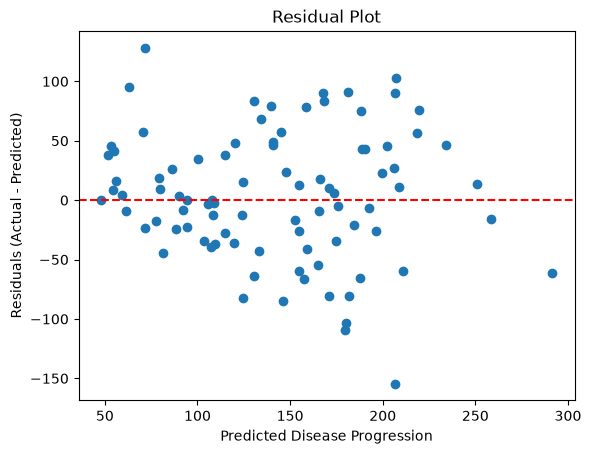

In [40]:
#residual plot
residuals = Y_test - Y_pred

plt.scatter(Y_pred, residuals)
plt.axhline(0, color='red', linestyle='--')
plt.xlabel('Predicted Disease Progression')
plt.ylabel('Residuals (Actual - Predicted)')
plt.title('Residual Plot')
plt.show()

Evaluate model performance

In [41]:
import numpy as np
mse = mean_squared_error(Y_test, Y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(Y_test, Y_pred)
print('MSE =', mse)
print('RMSE =', rmse)
print('R2 Score =', r2)

MSE = 2900.1936284934804
RMSE = 53.85344583676592
R2 Score = 0.4526027629719197


In [42]:
coef = pd.Series(model2.coef_, index=X.columns)
print(coef.abs().sort_values(ascending=False))

s1     931.488846
s5     736.198859
bmi    542.428759
s2     518.062277
bp     347.703844
s4     275.317902
sex    241.964362
s3     163.419983
s6      48.670657
age     37.904021
dtype: float64


Based on the absolute size of the coefficients (all features are on the same scale),
s1 has the largest coefficient (931), followed by s5 (736) and bmi (542). However,
s1 and s2 are highly correlated with each other (multicollinearity), so their
coefficients are inflated and partly cancel each other out. Therefore s5 and bmi are
the most reliable contributors to predicting disease progression, which is also
consistent with their strong correlation with the target in the heatmap. age and s6
contribute the least.

*Task 03:Experimentation*


Compare performance of simple vs. multivariate regression in terms of evaluation metrics.

In [43]:

def metrics(y_true, y_pred, p):
    mse = mean_squared_error(y_true, y_pred)
    r2 = r2_score(y_true, y_pred)
    n = len(y_true)
    adj = 1 - (1 - r2) * (n - 1) / (n - p - 1)
    return [mse, np.sqrt(mse), r2, adj]

results = pd.DataFrame(
    [metrics(y_test, y_pred, 1), metrics(Y_test, Y_pred, 10)],
    columns=['MSE', 'RMSE', 'R2', 'Adjusted R2'],
    index=['Simple (BMI only)', 'Multivariate (10 features)']
)
print(results.round(3))

                                 MSE    RMSE     R2  Adjusted R2
Simple (BMI only)           4061.826  63.732  0.233        0.225
Multivariate (10 features)  2900.194  53.853  0.453        0.382
